
# Zero-shot Benchmark — **SigLIP-L** (open_clip)

Notebook coerente con le versioni precedenti: stessa pipeline, metriche e salvataggi.
Pensato per **Colab + Google Drive** sul task di *architectural style classification*.

### Cosa fa
- Carica **SigLIP-L** via `open_clip` (`ViT-L-16-SigLIP`, pretrained `webli`)
- Esegue **zero-shot** con *prompt ensemble* + **temperature search**
- Calcola: **Top-1**, **Macro-F1**, **Top-5**, **Balanced Accuracy**, **Latency (ms/img)**
- Registra **GPU-h = 0.0** (zero-shot), **Effort umano (h)** e **Note**
- Appende i risultati a `benchmark_results.csv` (in `/content` e nella cartella del dataset in Drive)

> Modifica i parametri nella sezione **CONFIG** qui sotto.


In [5]:

# === Install ===
!pip -q install open_clip_torch scikit-learn matplotlib pandas tqdm
!pip -q install --upgrade "open_clip_torch>=2.24.0" "timm>=0.9.16"



In [9]:
#verifica i nomi supportati e scelta di SigLIP-l
import open_clip

# guarda cosa c'è nella tua versione
models = open_clip.list_models()
print([m for m in models if "SigLIP" in m or "siglip" in m])
# in genere vedrai qualcosa come: ['ViT-B-16-SigLIP', 'ViT-L-16-SigLIP', ...]
print(open_clip.list_pretrained("ViT-L-16-SigLIP2-384"))



['nllb-clip-base-siglip', 'nllb-clip-large-siglip', 'ViT-B-16-SigLIP', 'ViT-B-16-SigLIP2', 'ViT-B-16-SigLIP2-256', 'ViT-B-16-SigLIP2-384', 'ViT-B-16-SigLIP2-512', 'ViT-B-16-SigLIP-256', 'ViT-B-16-SigLIP-384', 'ViT-B-16-SigLIP-512', 'ViT-B-16-SigLIP-i18n-256', 'ViT-B-32-SigLIP2-256', 'ViT-gopt-16-SigLIP2-256', 'ViT-gopt-16-SigLIP2-384', 'ViT-L-16-SigLIP2-256', 'ViT-L-16-SigLIP2-384', 'ViT-L-16-SigLIP2-512', 'ViT-L-16-SigLIP-256', 'ViT-L-16-SigLIP-384', 'ViT-SO400M-14-SigLIP', 'ViT-SO400M-14-SigLIP2', 'ViT-SO400M-14-SigLIP2-378', 'ViT-SO400M-14-SigLIP-378', 'ViT-SO400M-14-SigLIP-384', 'ViT-SO400M-16-SigLIP2-256', 'ViT-SO400M-16-SigLIP2-384', 'ViT-SO400M-16-SigLIP2-512', 'ViT-SO400M-16-SigLIP-i18n-256']
['RN50:openai', 'RN50:yfcc15m', 'RN50:cc12m', 'RN101:openai', 'RN101:yfcc15m', 'RN50x4:openai', 'RN50x16:openai', 'RN50x64:openai', 'ViT-B-32:openai', 'ViT-B-32:laion400m_e31', 'ViT-B-32:laion400m_e32', 'ViT-B-32:laion2b_e16', 'ViT-B-32:laion2b_s34b_b79k', 'ViT-B-32:datacomp_xl_s13b_b90k',

In [10]:

# === Imports & Config ===
import os, time, json, math
from datetime import datetime
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
import open_clip
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score, classification_report, top_k_accuracy_score,
    f1_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Colab + Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# --------- CONFIG (MODIFICA QUI) ---------
DATA_ROOT = "/content/drive/MyDrive/ArchiStyles-2"  # cartella dataset
SPLIT = "test"               # "test" | "valid" | "train"
BATCH_SIZE = 32              # SigLIP-L è pesante: 32 è un punto di partenza

# Modello SigLIP-L
MODEL_NAME = "ViT-L-16-SigLIP2-384"
PRETRAINED = "webli"         # tipico checkpoint per SigLIP in open_clip

# Prompt templates
TEMPLATES = [
    "a photo of a {} building",
    "a photograph of {} architecture",
    "an example of {} architecture",
    "a building in {} style",
]

# Effort & note per la scorecard
EFFORT_HOURS = 0.5   # stima ore uomo per questa run
NOTES = "SigLIP-L zero-shot with prompt ensemble + temperature grid"
# -----------------------------------------

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Mounted at /content/drive
Using device: cuda


In [11]:

# === Model & Dataset ===
# Modello + preprocess

model, preprocess_train, preprocess_val = open_clip.create_model_and_transforms(
    model_name=MODEL_NAME,
    pretrained=PRETRAINED
)
# usa il preprocess di valid per l'inferenza
preprocess = preprocess_val

tokenizer = open_clip.get_tokenizer(MODEL_NAME)

model.to(device).eval()

# Dataset + DataLoader
assert os.path.isdir(DATA_ROOT), f"DATA_ROOT non trovato: {DATA_ROOT}"
split_path = os.path.join(DATA_ROOT, SPLIT)
assert os.path.isdir(split_path), f"Split '{SPLIT}' non trovato in {DATA_ROOT}"
ds = ImageFolder(split_path, transform=preprocess)
dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
classnames = ds.classes
num_classes = len(classnames)

print("Classi:", num_classes)
print("Esempio classi:", classnames[:10])


open_clip_model.safetensors:   0%|          | 0.00/3.53G [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/34.4M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/327 [00:00<?, ?B/s]

Classi: 25
Esempio classi: ['Achaemenid', 'American Foursquare', 'American craftsman style', 'Ancient Egyptian', 'Art Deco', 'Art Nouveau', 'Baroque', 'Bauhaus', 'Beaux-Arts', 'Byzantine']


In [12]:

# === Prompt generation & text features ===
def make_prompts(cname):
    return [t.format(cname) for t in TEMPLATES] + [f"{cname} architecture"]

# Tokenize prompts (prompt ensemble)
all_prompts, class_offsets = [], [0]
for cname in classnames:
    ps = make_prompts(cname)
    all_prompts.extend(ps)
    class_offsets.append(len(all_prompts))

tokens = tokenizer(all_prompts).to(device)

with torch.no_grad():
    text_features = model.encode_text(tokens)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

# Grid semplice per temperature (moltiplica i logits)
TEMP_GRID = [0.5, 1.0, 2.0]


In [13]:

# === Inference helpers ===
def evaluate_with_temp(temp):
    y_true, y_pred = [], []
    probs_collector = []
    model_dtype = next(model.parameters()).dtype

    with torch.no_grad():
        for imgs, labels in dl:
            imgs = imgs.to(device, dtype=model_dtype)
            img_features = model.encode_image(imgs)
            img_features = img_features / img_features.norm(dim=-1, keepdim=True)

            # logit scale nativo * temperature
            logit_scale = model.logit_scale.exp() * temp
            logits = logit_scale * (img_features @ text_features.T)

            # aggrega prompt per classe
            class_logits = []
            for i in range(num_classes):
                s, e = class_offsets[i], class_offsets[i+1]
                class_logits.append(logits[:, s:e].mean(dim=1))
            class_logits = torch.stack(class_logits, dim=1)

            prob = class_logits.softmax(dim=-1)
            pred = prob.argmax(dim=-1)

            y_true.extend(labels.tolist())
            y_pred.extend(pred.tolist())
            probs_collector.append(prob.cpu().numpy())

    y_true = np.array(y_true, dtype=int)
    y_pred = np.array(y_pred, dtype=int)
    probs = np.concatenate(probs_collector, axis=0)

    top1 = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    top5 = top_k_accuracy_score(y_true, probs, k=min(5, num_classes), labels=np.arange(num_classes))
    bal_acc = balanced_accuracy_score(y_true, y_pred)

    return top1, macro_f1, top5, bal_acc, y_true, y_pred, probs


In [14]:

# === Temperature search (nota: per rigore andrebbe su VALID) ===
best = None
for t in TEMP_GRID:
    top1, macro_f1, top5, bal_acc, _, _, _ = evaluate_with_temp(t)
    print(f"temp={t:.2f} -> top1={top1:.4f}  macroF1={macro_f1:.4f}  top5={top5:.4f}  balAcc={bal_acc:.4f}")
    if best is None or top1 > best[0]:
        best = (top1, macro_f1, top5, bal_acc, t)

best_top1, best_macro_f1, best_top5, best_bal_acc, best_temp = best
print("\nBest temperature:", best_temp)


temp=0.50 -> top1=0.6976  macroF1=0.6933  top5=0.9624  balAcc=0.6962
temp=1.00 -> top1=0.6976  macroF1=0.6933  top5=0.9624  balAcc=0.6962
temp=2.00 -> top1=0.6976  macroF1=0.6933  top5=0.9624  balAcc=0.6962

Best temperature: 0.5


In [15]:

# === Final evaluation + latency + report & confusion matrix ===
top1, macro_f1, top5, bal_acc, y_true, y_pred, probs = evaluate_with_temp(best_temp)

# Latency (ms/img)
def measure_latency(num_batches=20):
    model_dtype = next(model.parameters()).dtype
    # warmup
    it = iter(dl)
    for _ in range(3):
        try:
            imgs, _ = next(it)
        except StopIteration:
            it = iter(dl)
            imgs, _ = next(it)
        imgs = imgs.to(device, dtype=model_dtype)
        with torch.no_grad():
            _ = model.encode_image(imgs)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    # timed
    times = []
    it = iter(dl)
    for _ in range(num_batches):
        try:
            imgs, _ = next(it)
        except StopIteration:
            it = iter(dl)
            imgs, _ = next(it)
        imgs = imgs.to(device, dtype=model_dtype)
        t0 = time.time()
        with torch.no_grad():
            _ = model.encode_image(imgs)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        dt = time.time() - t0
        ms_per_img = (dt / imgs.size(0)) * 1000.0
        times.append(ms_per_img)
    return float(np.mean(times))

latency_ms = measure_latency(num_batches=min(20, math.ceil(len(ds)/BATCH_SIZE)))
gpu_hours = 0.0  # zero-shot

print(f"FINAL -> Top-1={top1:.4f} | Macro-F1={macro_f1:.4f} | Top-5={top5:.4f} | BalAcc={bal_acc:.4f}")
print(f"Latency: {latency_ms:.1f} ms/img | GPU-h: {gpu_hours:.2f}")


FINAL -> Top-1=0.6976 | Macro-F1=0.6933 | Top-5=0.9624 | BalAcc=0.6962
Latency: 108.9 ms/img | GPU-h: 0.00


                          precision    recall  f1-score   support

              Achaemenid     0.8649    0.9697    0.9143        33
     American Foursquare     0.5429    0.6786    0.6032        28
American craftsman style     0.6842    0.5200    0.5909        25
        Ancient Egyptian     1.0000    0.8519    0.9200        27
                Art Deco     0.7500    0.6000    0.6667        35
             Art Nouveau     0.8571    0.7500    0.8000        24
                 Baroque     0.5676    0.6774    0.6176        31
                 Bauhaus     0.6957    0.6957    0.6957        23
              Beaux-Arts     0.4030    0.7714    0.5294        35
               Byzantine     0.7188    0.8214    0.7667        28
          Chicago school     0.5909    0.4643    0.5200        28
                Colonial     0.7059    0.4000    0.5106        30
        Deconstructivism     0.8056    0.8529    0.8286        34
               Edwardian     0.7143    0.5172    0.6000        29
         

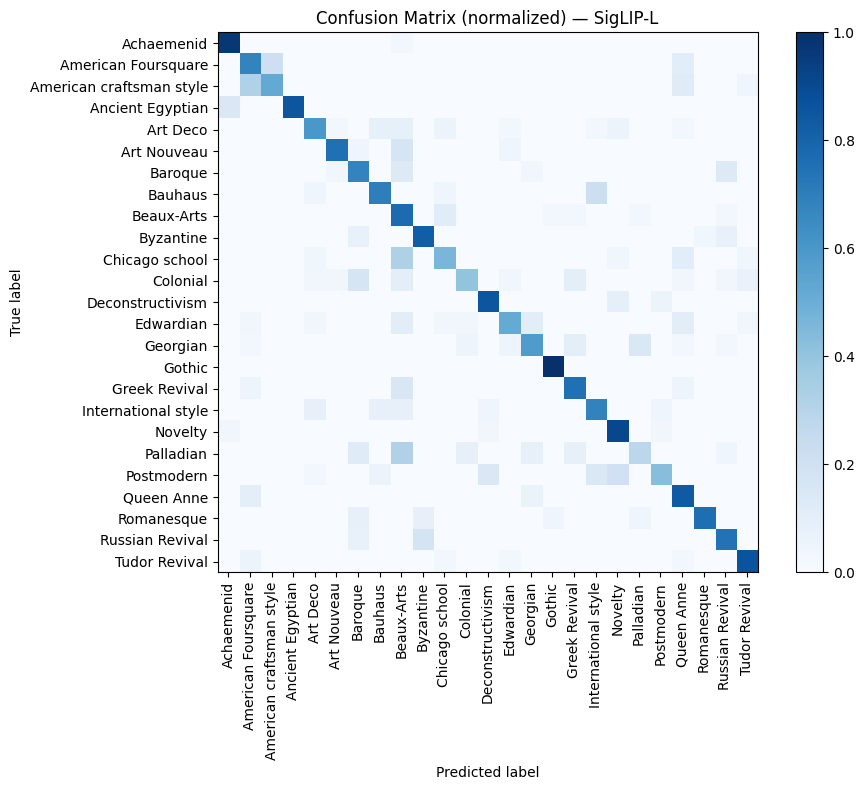

In [16]:

# === Classification report & confusion matrix ===
print(classification_report(y_true, y_pred, target_names=classnames, digits=4, zero_division=0))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=classnames,
    normalize="true",
    cmap="Blues",
    include_values=False,
    xticks_rotation=90,
    ax=ax
)
ax.set_title("Confusion Matrix (normalized) — SigLIP-L")
plt.tight_layout()
plt.show()


In [17]:

# === Save results row to CSV ===
row = {
    "Timestamp": datetime.utcnow().isoformat(),
    "Model": MODEL_NAME,
    "Pretrained": PRETRAINED,
    "Scenario": f"Zero-shot ({SPLIT})",
    "Techniques": "Prompt ensemble + temperature search",
    "Top-1 Acc": round(float(top1), 4),
    "Macro-F1": round(float(macro_f1), 4),
    "Top-5 Acc": round(float(top5), 4),
    "Balanced Acc": round(float(bal_acc), 4),
    "GPU-h": gpu_hours,
    "Latency (ms/img)": round(float(latency_ms), 1),
    "Effort umano (h)": float(EFFORT_HOURS),
    "Note": NOTES,
    "Classes": int(len(classnames)),
    "Batch size": int(BATCH_SIZE)
}

df = pd.DataFrame([row])
display(df)

# Salva in locale
csv_path_local = "/content/benchmark_results.csv"
if os.path.exists(csv_path_local):
    old = pd.read_csv(csv_path_local)
    out = pd.concat([old, df], ignore_index=True)
else:
    out = df.copy()
out.to_csv(csv_path_local, index=False)

# Salva anche nella cartella del dataset su Drive
csv_path_drive = os.path.join(DATA_ROOT, "benchmark_results.csv")
try:
    if os.path.exists(csv_path_drive):
        old_d = pd.read_csv(csv_path_drive)
        out_d = pd.concat([old_d, df], ignore_index=True)
    else:
        out_d = df.copy()
    out_d.to_csv(csv_path_drive, index=False)
    print("Saved CSV to:", csv_path_local, "and", csv_path_drive)
except Exception as e:
    print("Saved CSV to:", csv_path_local)
    print("Drive save failed:", e)


/tmp/ipython-input-2971794759.py:3: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "Timestamp": datetime.utcnow().isoformat(),


,Timestamp,Model,Pretrained,Scenario,Techniques,Top-1 Acc,Macro-F1,Top-5 Acc,Balanced Acc,GPU-h,Latency (ms/img),Effort umano (h),Note,Classes,Batch size
0,2025-08-21T10:56:47.195384,ViT-L-16-SigLIP2-384,webli,Zero-shot (test),Prompt ensemble + temperature search,0.6976,0.6933,0.9624,0.6962,0.0,108.9,0.5,SigLIP-L zero-shot with prompt ensemble + temp...,25,32


Saved CSV to: /content/benchmark_results.csv and /content/drive/MyDrive/ArchiStyles-2/benchmark_results.csv
